# DM-2 — Partie 1 : AdaBoost sur MNIST

On teste AdaBoost sur des tâches binaires de MNIST  en faisant varier :
- le classifieur faible (stump, arbres de profondeur 2/3/5, perceptron)
- le nombre d'étapes de boosting (10, 50, 100, 200)
- la tâche binaire (3 vs 8, 4 vs 9, {0-4} vs {5-9})

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import time

warnings.filterwarnings("ignore")
SEED = 42

# 1. Chargement des données

(70000, 784) (70000,)


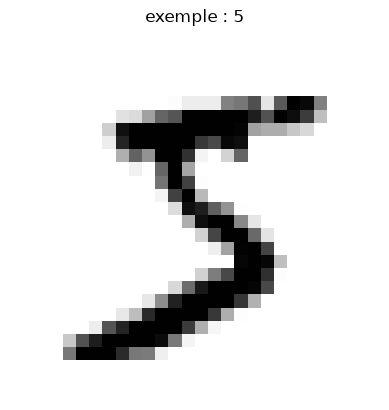

In [3]:
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X = X.astype(np.float32) / 255.0
y = y.astype(int)
print(X.shape, y.shape)

plt.imshow(X[0].reshape(28, 28), cmap="gray_r")
plt.title(f"exemple : {y[0]}")
plt.axis("off")
plt.show()

## 2. Paramètres des expériences

In [4]:
N_MAX = 200                 # un seul entraînement à 200 étapes, évalué aux étapes intermédiaires
STEPS = [10, 50, 100, 200]

# tâches
tasks = {
    "3_vs_8": ([3], [8]),
    "4_vs_9": ([4], [9]),
    "0-4_vs_5-9": ([0, 1, 2, 3, 4], [5, 6, 7, 8, 9]),
}

weak_learners = {
    "stump (prof.1)": DecisionTreeClassifier(max_depth=1, random_state=SEED),
    "arbre prof.2": DecisionTreeClassifier(max_depth=2, random_state=SEED),
    "arbre prof.3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "arbre prof.5": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "perceptron": Perceptron(max_iter=15, tol=1e-3, random_state=SEED),
}

## 3. Expériences et matrices de confusion

Pour chaque tâche j'imprime une grille de matrices de confusion


Je stocke les métriques dans `rows` pour le tableau récapitulatif.

3_vs_8       stump (prof.1)  : 200 étapes effectivement utilisées, temps = 69.0s
3_vs_8       arbre prof.2    : 200 étapes effectivement utilisées, temps = 68.2s
3_vs_8       arbre prof.3    : 200 étapes effectivement utilisées, temps = 103.8s
3_vs_8       arbre prof.5    : 200 étapes effectivement utilisées, temps = 153.0s
3_vs_8       perceptron      : 19 étapes effectivement utilisées, temps = 3.0s


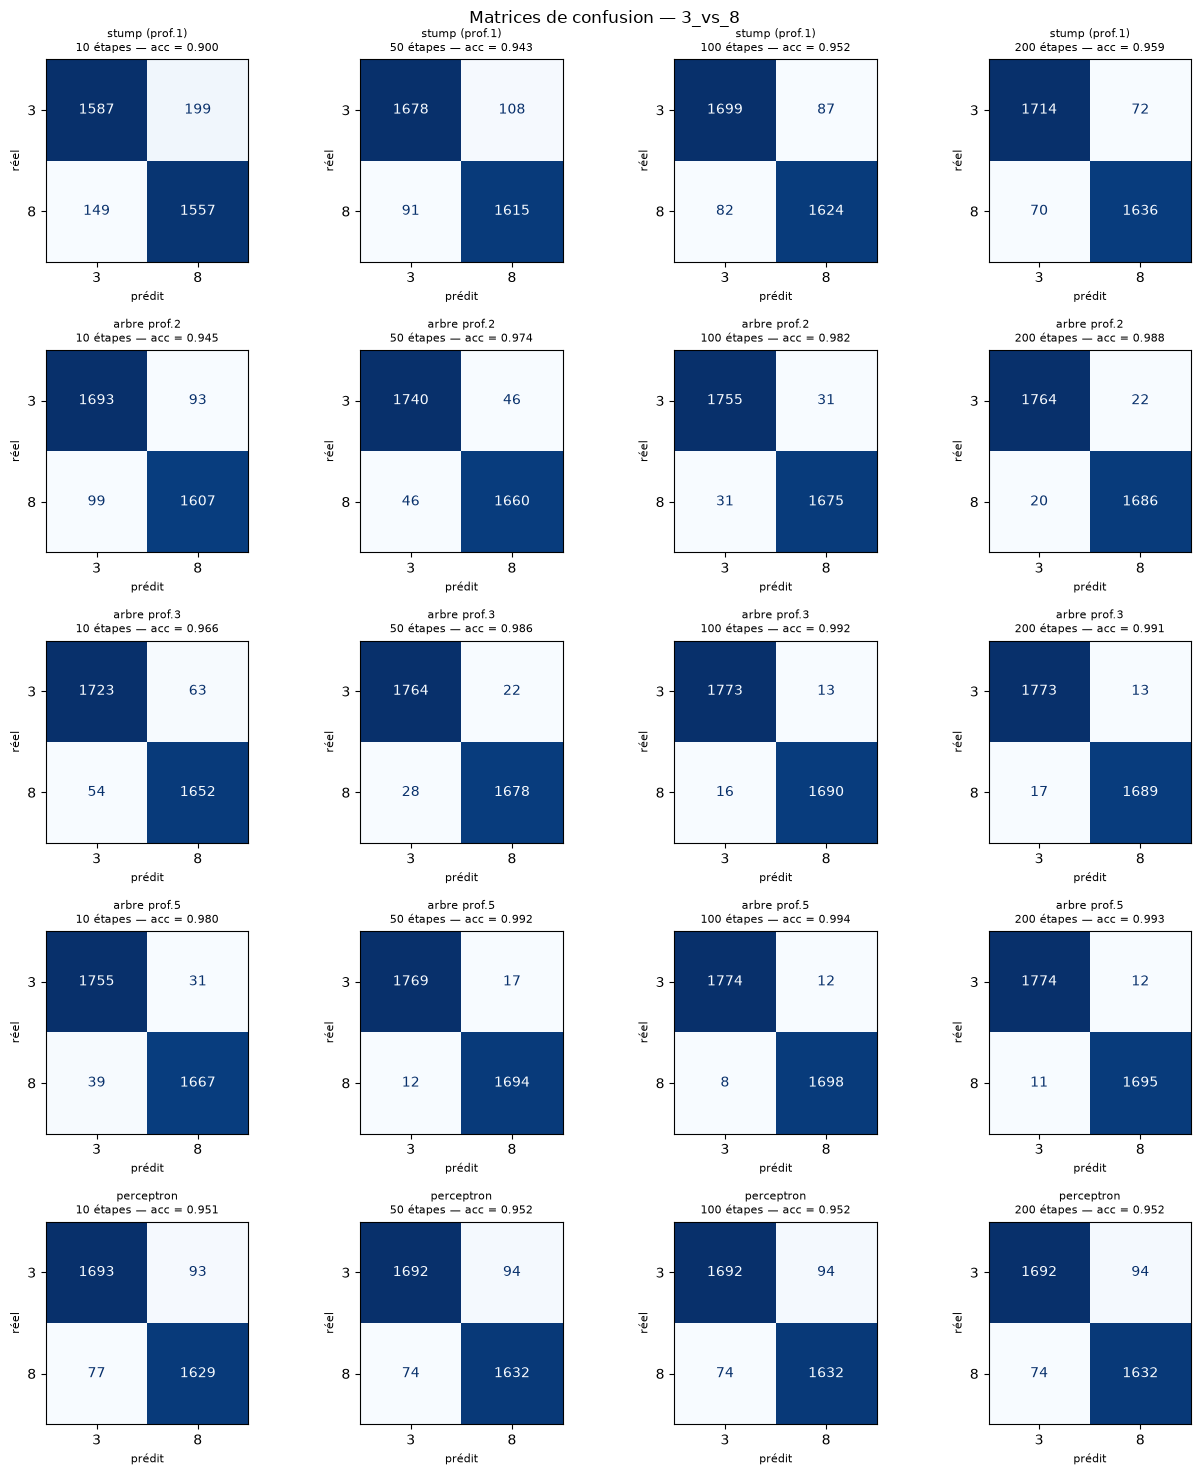

4_vs_9       stump (prof.1)  : 200 étapes effectivement utilisées, temps = 41.6s
4_vs_9       arbre prof.2    : 200 étapes effectivement utilisées, temps = 115.9s
4_vs_9       arbre prof.3    : 200 étapes effectivement utilisées, temps = 91.2s
4_vs_9       arbre prof.5    : 200 étapes effectivement utilisées, temps = 137.1s
4_vs_9       perceptron      : 19 étapes effectivement utilisées, temps = 3.0s


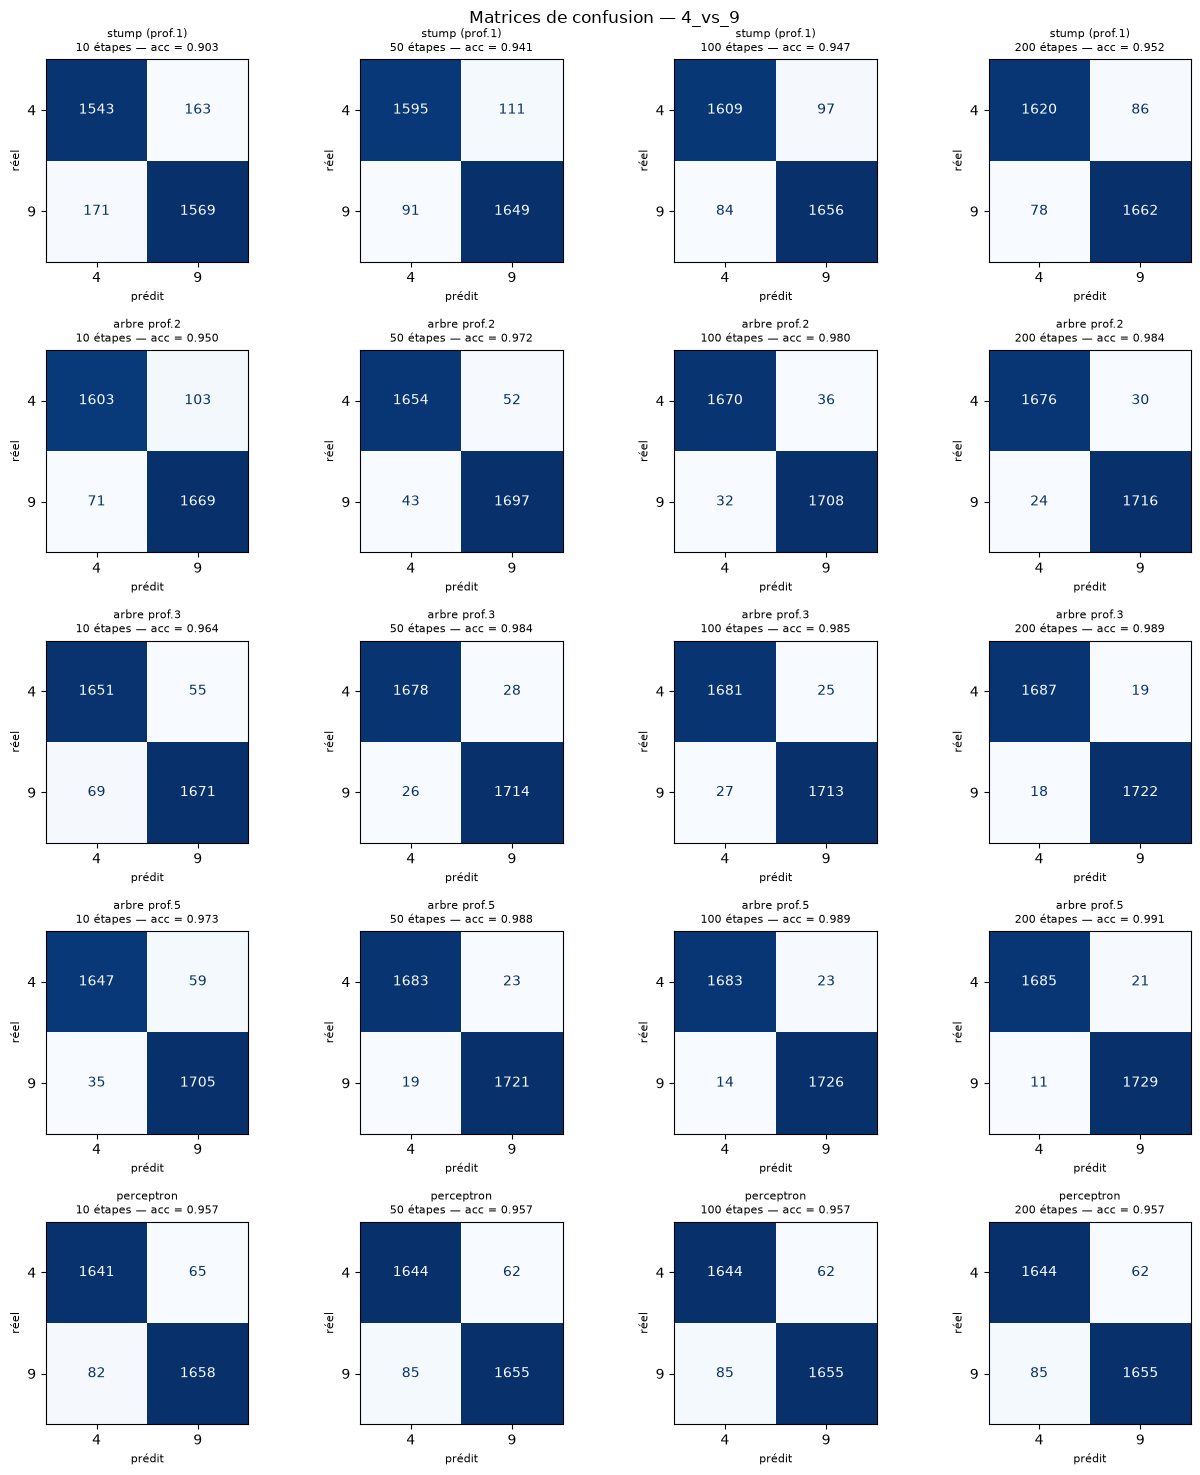

0-4_vs_5-9   stump (prof.1)  : 200 étapes effectivement utilisées, temps = 54.7s
0-4_vs_5-9   arbre prof.2    : 200 étapes effectivement utilisées, temps = 102.6s
0-4_vs_5-9   arbre prof.3    : 200 étapes effectivement utilisées, temps = 150.8s
0-4_vs_5-9   arbre prof.5    : 200 étapes effectivement utilisées, temps = 244.1s
0-4_vs_5-9   perceptron      : 16 étapes effectivement utilisées, temps = 2.5s


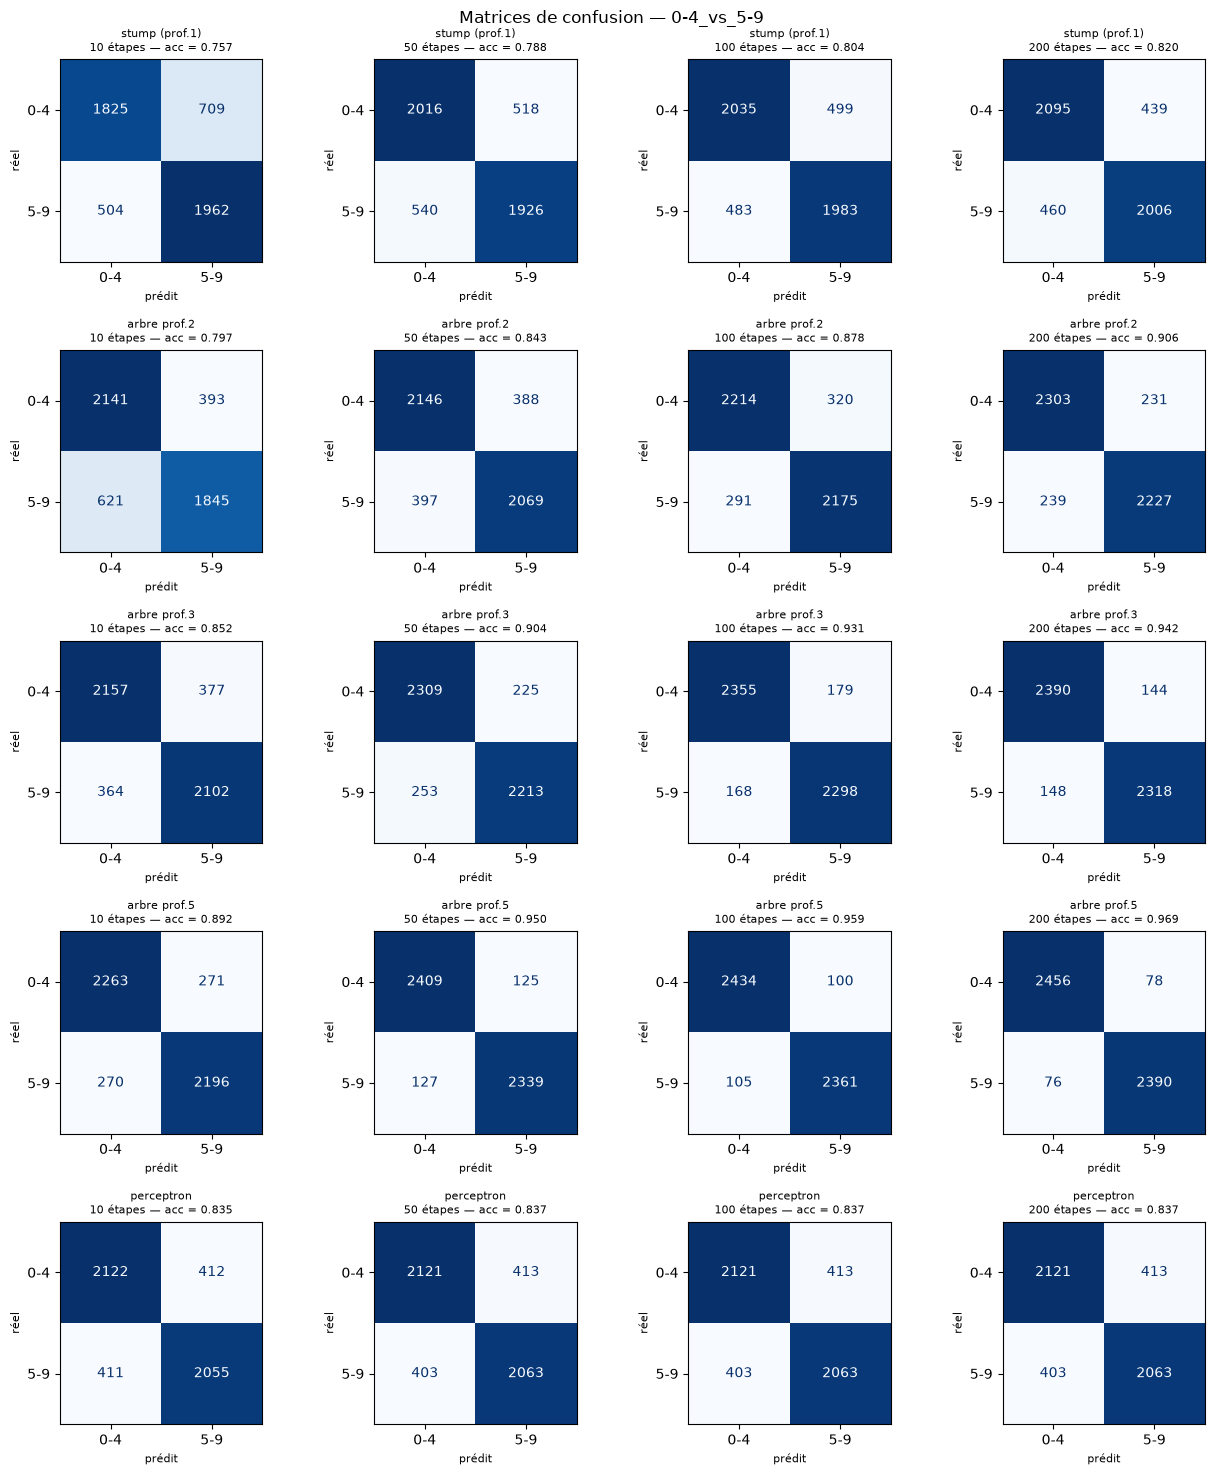

In [4]:
rows = []

for task, (c0, c1) in tasks.items():
    # données de la tâche (classe 0 / classe 1)
    mask = np.isin(y, c0 + c1)
    Xt, yt = X[mask], np.isin(y[mask], c1).astype(int)

    # Si on fait tourner sur ordinateur décommenter cette section pour éviter de perdre trop de temps à l'entraînement


    if len(yt) > 20000:   # sous-échantillonnage pour limiter le temps de calcul    # Section a commenter/décommenter selon la machine utilisée
        idx = np.random.RandomState(SEED).choice(len(yt), 20000, replace=False)     # Section a commenter/décommenter selon la machine utilisée
        Xt, yt = Xt[idx], yt[idx]                                                   # Section a commenter/décommenter selon la machine utilisée
    
    Xtr, Xte, ytr, yte = train_test_split(Xt, yt, test_size=0.25, stratify=yt, random_state=SEED)

    noms = [str(c0[0]) if len(c0) == 1 else f"{c0[0]}-{c0[-1]}",
            str(c1[0]) if len(c1) == 1 else f"{c1[0]}-{c1[-1]}"]

    fig, axes = plt.subplots(len(weak_learners), len(STEPS), squeeze=False,
                             figsize=(3.2 * len(STEPS), 3.0 * len(weak_learners)))

   

    for i, (wname, base) in enumerate(weak_learners.items()):
        t = time.time()
        ada = AdaBoostClassifier(estimator=base, n_estimators=N_MAX, random_state=SEED)
        ada.fit(Xtr, ytr)
        preds = list(ada.staged_predict(Xte))   # prédictions après n étapes
        print(f"{task:12s} {wname:15s} : {len(preds)} étapes effectivement utilisées, temps = {time.time() - t:.1f}s")

        for j, s in enumerate(STEPS):
            s_eff = min(s, len(preds))          # AdaBoost peut s'arrêter avant N_MAX et il le fait pour le perceptron
            p = preds[s_eff - 1]
            cm = confusion_matrix(yte, p, labels=[0, 1])
            prec, rapp, f1, _ = precision_recall_fscore_support(yte, p, average="binary", zero_division=0)
            acc = (p == yte).mean()
            rows.append(dict(tache=task, faible=wname, etapes=s, etapes_utilisees=s_eff,
                             accuracy=acc, precision=prec, rappel=rapp, f1=f1,
                             TN=cm[0, 0], FP=cm[0, 1], FN=cm[1, 0], TP=cm[1, 1]))

            ax = axes[i, j]
            ConfusionMatrixDisplay(cm, display_labels=noms).plot(ax=ax, colorbar=False, cmap="Blues")
            ax.set_title(f"{wname}\n{s} étapes — acc = {acc:.3f}", fontsize=8)
            ax.set_xlabel("prédit", fontsize=8)
            ax.set_ylabel("réel", fontsize=8)

    fig.suptitle(f"Matrices de confusion — {task}", fontsize=12)
    fig.tight_layout()
    plt.show()

## 5. Bilan

On peut voir que :

- Avec les perceptrons en classifieur faible  donc quis'aprennent rapidement il n'y arrive pas du tout car il s'arrête très rapidement (moins de 10 itérations) car l'erreur est plus grande que le hasard assez rapidement ce qui fait qu'adaBoost arrête le processus donc ce n'est pas un bon apprenant faible
- Pour les arbres,  plus la profondeur des apprenants faibles est grande, moins l'algorithme fait d'erreur il n'y a pas de surapprentissage mais cela demande par contre plus de temps de calcul (entre 40s et 150s pour 200 étapes)
- Le temps de calcul est démultiplié pour 0-4 vs 5-9 notamment parce qu'il y a beaucoup plus de données à traiter c'est pourquoi j'ai limité le nombre de données 
- La classe qui est de manière générale la plus facile à différencier par les algorithmes entre les trois testée est  3 vs 8 puis 4 vs 9 puis 0-4 vs 5-9 comme on peut le voir dans les matrices de confusion

--------------
# Partie 2

On veut maintenant regarder les cartes de saillances pour les différentes combinaisons de paramètres testées dans la première partie. On commence par créer les fonctions qu'on va utiliser pour l'obtention des cartes de saillance:

In [5]:
def split_task(task):
    """
    Fonction de découpage des données pour pouvoir reproduire les modèles de la partie 1 sur les mêmes données
    (sous-échantillon 20000 + split 75/25, SEED fixe pour reproductabilitée).
    """
    c0, c1 = tasks[task]
    mask = np.isin(y, c0 + c1)
    Xt, yt = X[mask], np.isin(y[mask], c1).astype(int)
    if len(yt) > 20000:
        idx = np.random.RandomState(SEED).choice(len(yt), 20000, replace=False)
        Xt, yt = Xt[idx], yt[idx]
    return train_test_split(Xt, yt, test_size=0.25, stratify=yt, random_state=SEED)


def saliency(ada, n_steps, signed=False):
    """Carte 28x28 construite à partir des n_steps premiers apprenants faibles."""
    m = np.zeros(784)
    for est, alpha in zip(ada.estimators_[:n_steps], ada.estimator_weights_[:n_steps]):
        if isinstance(est, Perceptron):
            m += alpha * (est.coef_[0] if signed else np.abs(est.coef_[0]))
        elif signed:
            assert est.max_depth == 1, "carte signée définie seulement pour les stumps"
            t = est.tree_
            if t.node_count == 3:  # racine + 2 feuilles
                # nœud 1 = fils gauche (pixel <= seuil), nœud 2 = fils droit (pixel > seuil)
                m[t.feature[0]] += alpha * (t.value[2][0].argmax() - t.value[1][0].argmax())
        else:
            m += alpha * est.feature_importances_
    return m.reshape(28, 28)

On choisit les modèles pour lesquels on veut obtenir les cartes et on les entraine en les stockant pour générer les cartes après

In [6]:
SAL_LEARNERS = ["stump (prof.1)", "arbre prof.3", "perceptron"]

models = {}
for task in tasks:
    Xtr, Xte, ytr, yte = split_task(task)
    for w in SAL_LEARNERS:
        models[(task, w)] = AdaBoostClassifier(estimator=weak_learners[w], n_estimators=N_MAX,
                                               random_state=SEED).fit(Xtr, ytr)
        print(task, w, "OK")

3_vs_8 stump (prof.1) OK
3_vs_8 arbre prof.3 OK
3_vs_8 perceptron OK
4_vs_9 stump (prof.1) OK
4_vs_9 arbre prof.3 OK
4_vs_9 perceptron OK
0-4_vs_5-9 stump (prof.1) OK
0-4_vs_5-9 arbre prof.3 OK
0-4_vs_5-9 perceptron OK


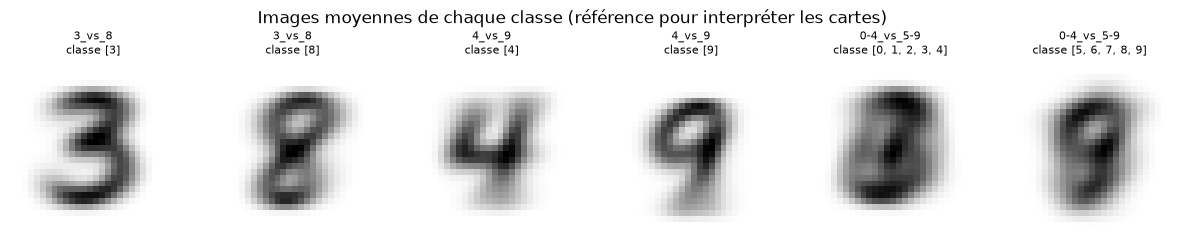

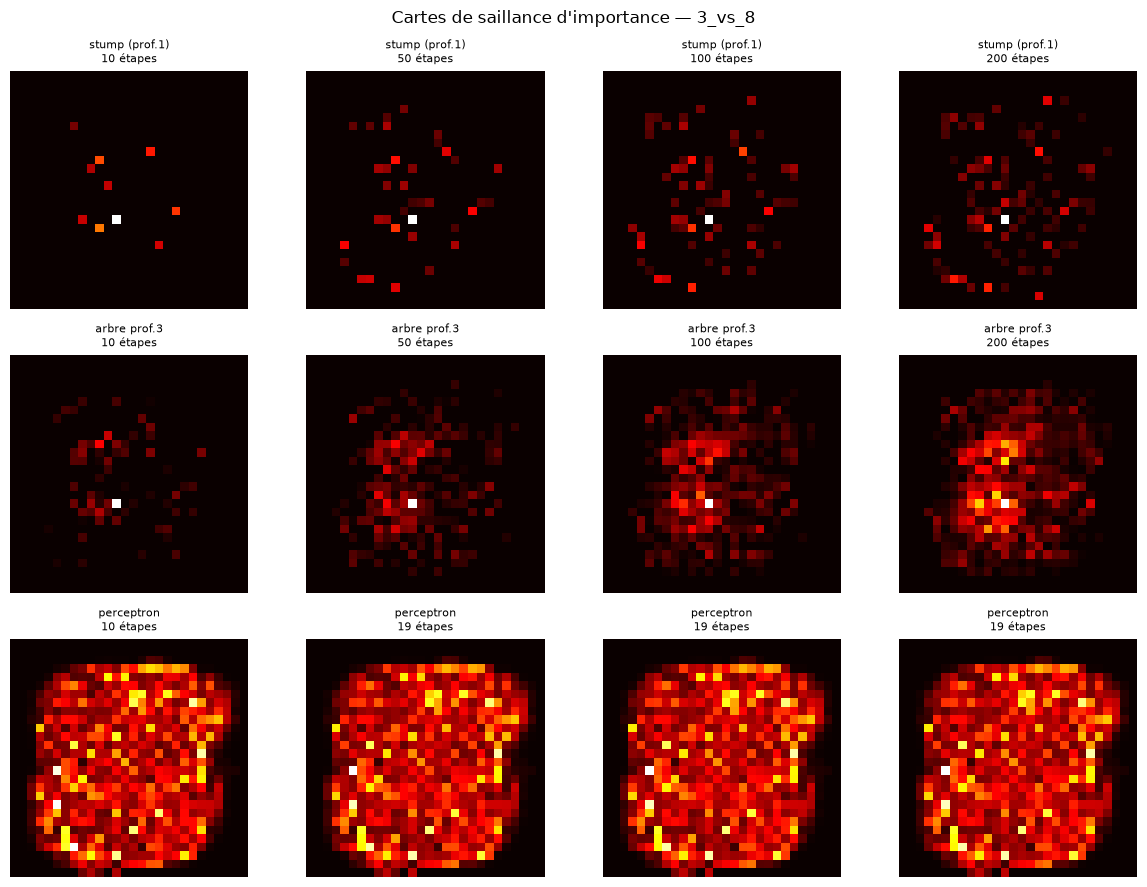

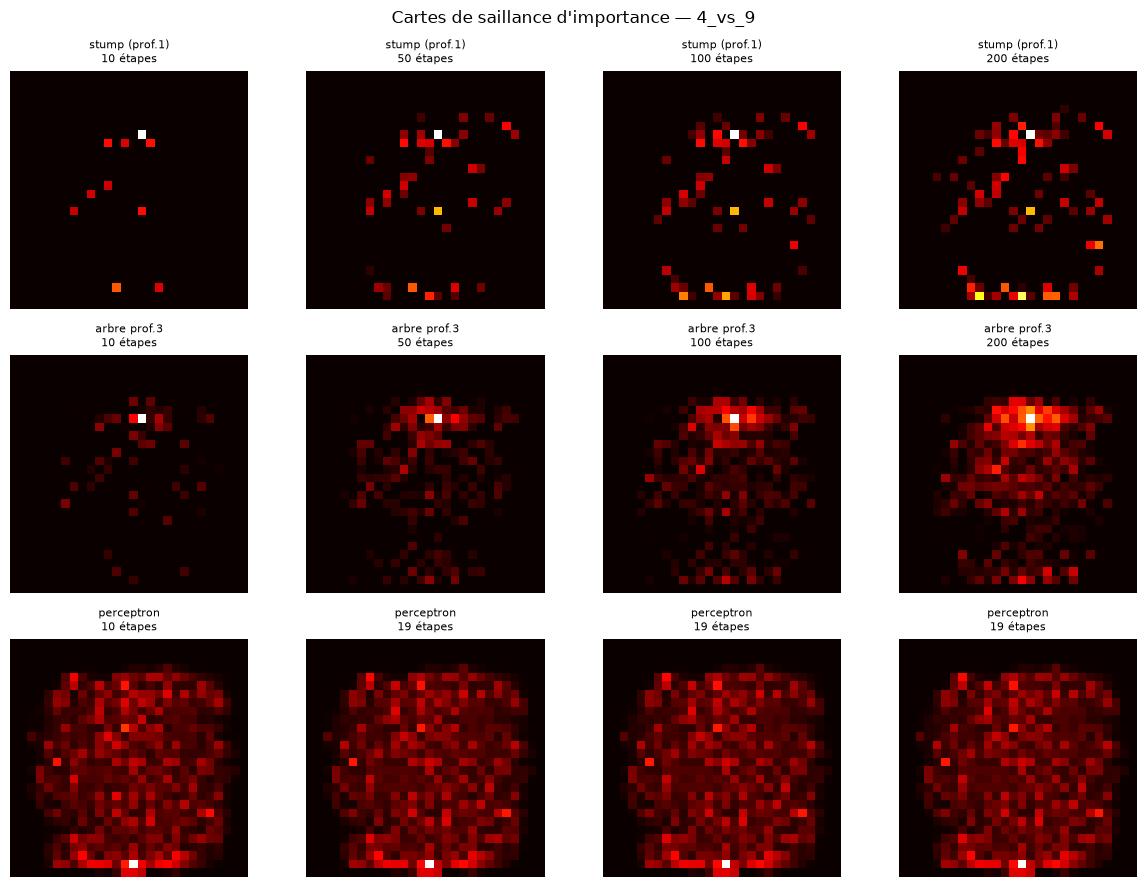

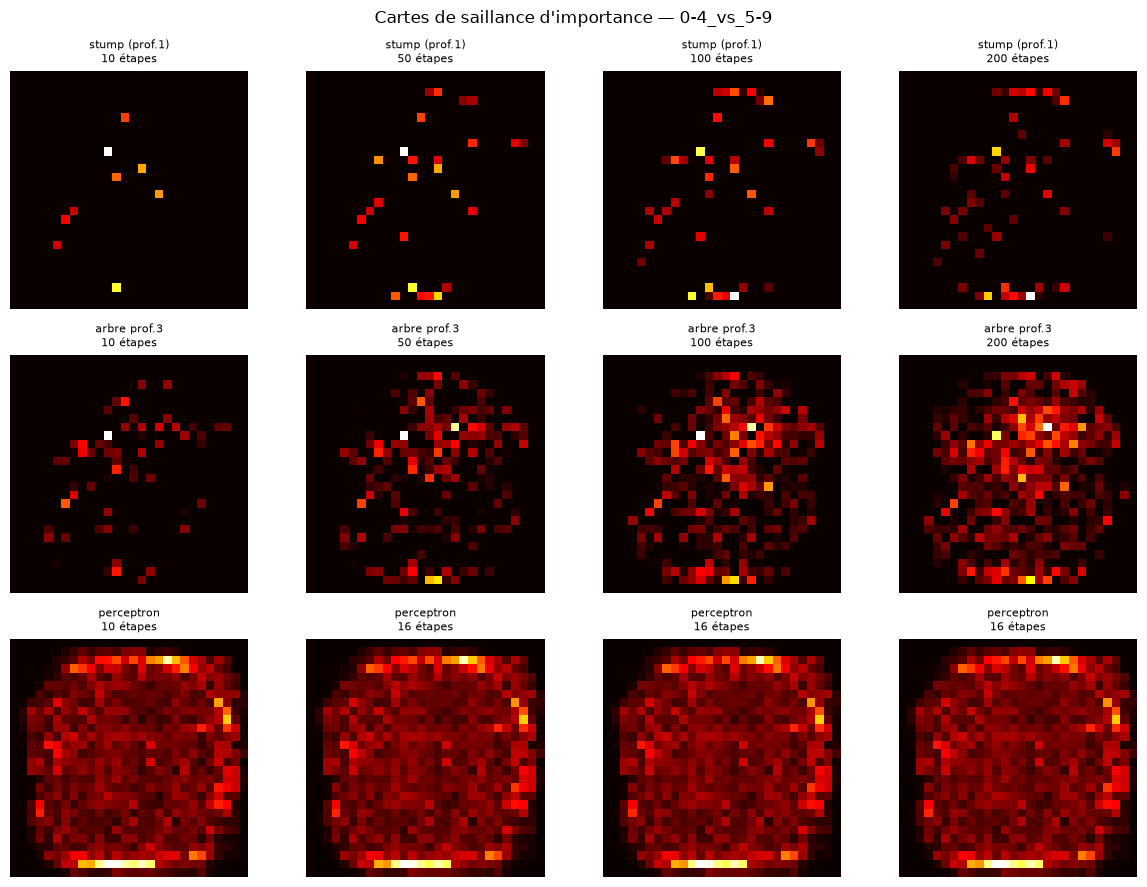

In [ ]:
def plot_task(task, learners, signed=False):
    """
    """
    fig, axes = plt.subplots(len(learners), len(STEPS), squeeze=False,
                             figsize=(3 * len(STEPS), 3 * len(learners)))
    for i, w in enumerate(learners):
        ada = models[(task, w)]
        for j, s in enumerate(STEPS):
            m = saliency(ada, s, signed)
            v = np.abs(m).max() or 1
            axes[i, j].imshow(m, cmap="bwr" if signed else "hot",
                              vmin=-v if signed else 0, vmax=v)
            axes[i, j].set_title(f"{w}\n{min(s, len(ada.estimators_))} étapes", fontsize=8)
            axes[i, j].axis("off")
    fig.suptitle(f"Cartes de saillance {'signées' if signed else 'd\'importance'} — {task}")
    fig.tight_layout()
    plt.show()

# Images moyennes de chaque classe (référence pour interpréter les cartes)
fig, axes = plt.subplots(1, 2 * len(tasks), figsize=(5 * len(tasks), 2.8))
k = 0
for task, (c0, c1) in tasks.items():
    for c in (c0, c1):
        axes[k].imshow(X[np.isin(y, c)].mean(0).reshape(28, 28), cmap="gray_r")
        axes[k].set_title(f"{task}\nclasse {c}", fontsize=8)
        axes[k].axis("off")
        k += 1
fig.suptitle("Images moyennes de chaque classe (référence pour interpréter les cartes)", fontsize=12)
plt.show()

for task in tasks:
    plot_task(task, SAL_LEARNERS, signed=False)            # importance, tous les apprenants
    

Les cartes de saillance nous apporte beaucoup d'informations sur ce que fait vraiment le modèle. Ainsi, on vois que pour les stumps les premières étapes ont très peu de poids, car un arbre est créé par étapes. Au contraire, les perceptron ont imédiatement des poids sur l'entièreté de la figure, ce qui leur permet de converger bien plus rapidement. Pour interpréter les cartes de saillances, il est plus simple de regarder les arbres de profondeur 3, qui présente plus de poids que ceux de profondeur 1 mais pas autant que les perceptrons. 

Ainsi, on peu remarquer des zones intéressantes, par exemple sur la comparaison 3-8, on voit deux zones de poid fort, au niveau de la gauche du chiffre, là où se trouve la différence entre les deux symboles (ouvert pour le 3 et fermé pour le 8, voir figure de moyenne de chaque carte). De même, pour le 4 et le 9, où la différence majeure se trouve sur le haut du symbole (ouvert pour le 4 et fermé pour le 9, voir figure de moyenne de chaque carte)

Pour les stumps et les perceptrons, on a une profondeur de 1, donc on peut aussi directement regarder le signe des poids, pour en interpréter l'usage.

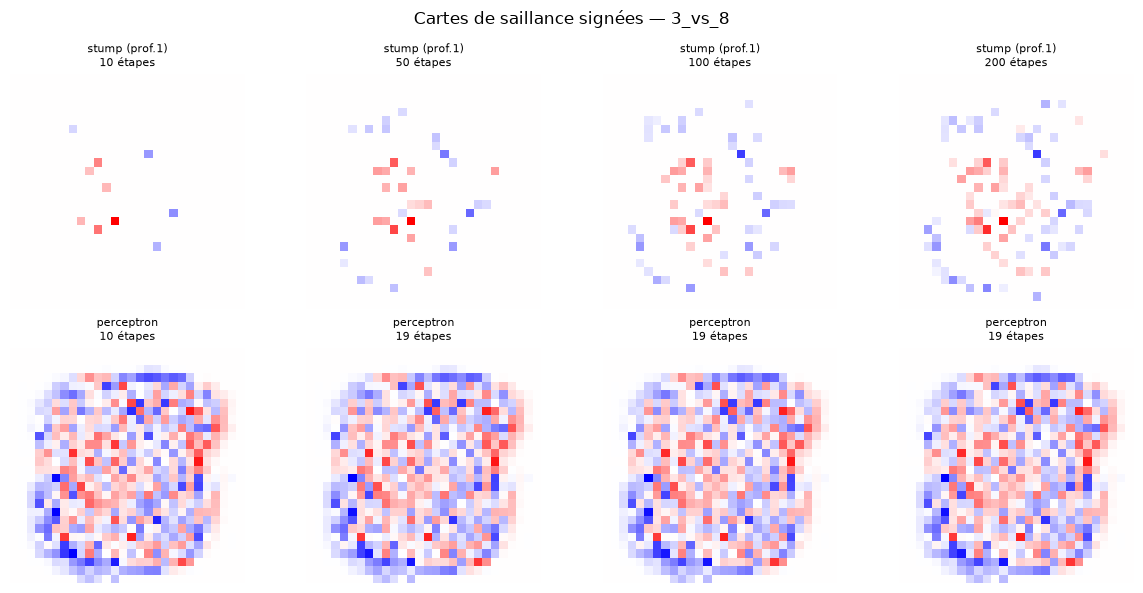

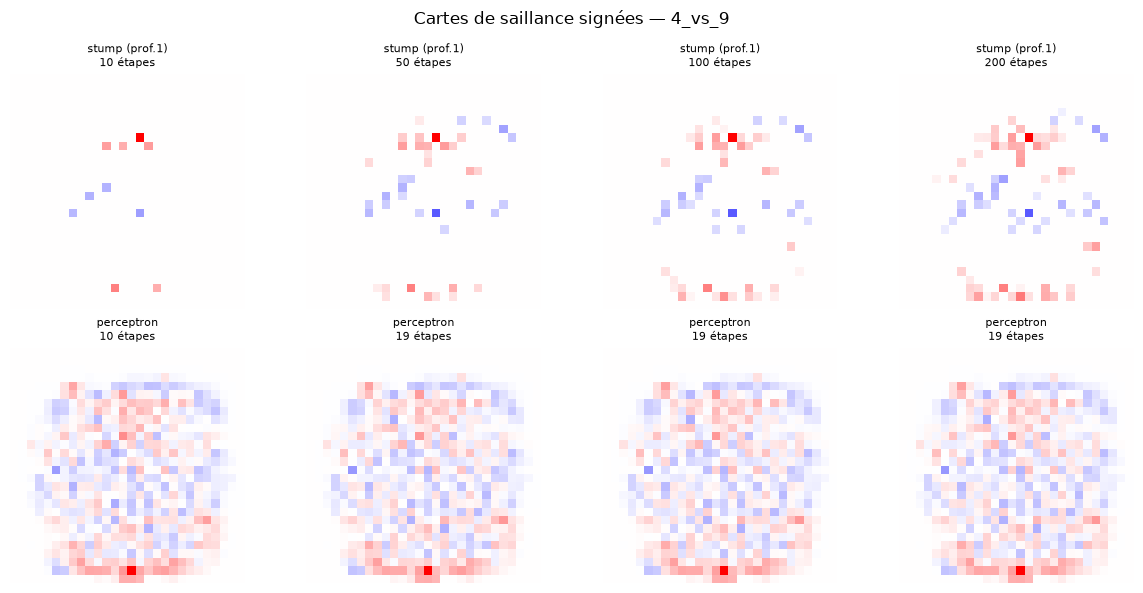

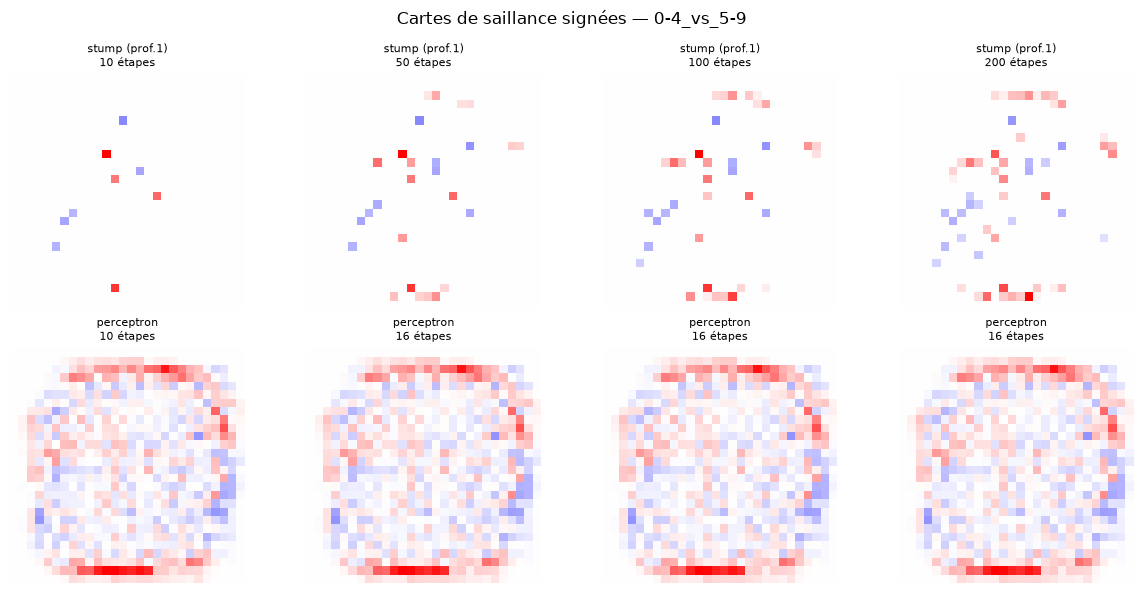

In [9]:
for task in tasks:
    plot_task(task, ["stump (prof.1)", "perceptron"], signed=True)

Ici, on voit bien que certaine zones servent à favoriser une classe face à une autre, mais la répartition des poids est bien plus dure à interpréter car elle est soit trop lacunaire soit trop complexe. Néanmoins, on peut remarquer des tendance, comme des poids globalement positif au milieu gauche dans la comparaison 3-8 ou une structure en bande horizontale pour la comparaison 4-9 (sur les stumps)